In [1]:
from __future__ import annotations

import math
import re
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, LogFormatterMathtext, NullLocator

# Figure 13(a)

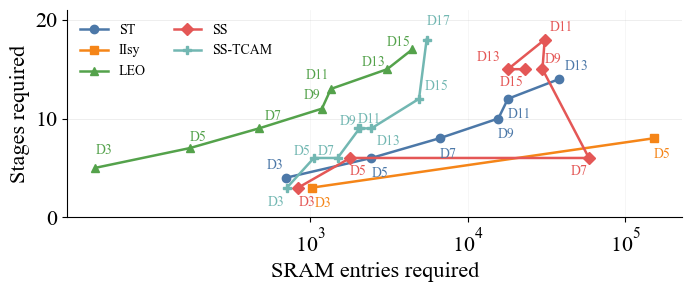

In [2]:
FEATURE_COUNT = 9
STAGE_LIMIT = 20
DATA_FILE = Path("data/all_dt_ciciot22.txt")

NON_DEPLOYABLE = {
    "failed",
    "missing_converter",
    "N/A",
    "pending",
    "skipped_after_failure",
}

COLUMNS = [
    "feature",
    "depth",
    "tree",
    "max_leaves",
    "leaves",
    "acc",
    "macro_f1",
    "st",
    "st_tcam",
    "iisy",
    "iisy_range",
    "leo_tcam",
    "leo_sram",
    "ss",
    "ss_greedy",
    "ss_range_sram",
    "ss_range_tcam",
]
SOURCE_COLUMNS = {
    "iisy": ("iisy", "iisy_range"),
    "leo": ("leo_tcam", "leo_sram"),
    "ss_light": ("ss", "ss_range_sram"),
    "st": ("st", "st_tcam"),
}


@dataclass(frozen=True)
class MetricValue:
    entries: int
    rendered_blocks: int | None = None


@dataclass(frozen=True)
class Row:
    feature: int
    depth: int
    max_leaves: int | None
    macro_f1: float
    values: dict[str, MetricValue | None]


@dataclass(frozen=True)
class Point:
    depth: int
    max_leaves: int | None
    macro_f1: float
    entries: int
    stages: int


@dataclass(frozen=True)
class Scheme:
    key: str
    label: str
    marker: str
    color: str
    stage_count: Callable[[Row, MetricValue], int]


def stage_switchtree(row: Row, value: MetricValue) -> int:
    del value
    return row.depth + 1


def stage_iisy(row: Row, value: MetricValue) -> int:
    del row
    for entry_limit, extra_stages in ((32768, 1), (65536, 2), (131072, 3), (262144, 6)):
        if value.entries <= entry_limit:
            return 2 + extra_stages
    return STAGE_LIMIT + 1  # Exclude configurations above the supported entry limit.


def stage_leo_sram(row: Row, value: MetricValue) -> int:
    del value
    flattened_layers = math.ceil(row.depth / 2)
    return 2 * flattened_layers + 1


def stage_rendered_blocks(row: Row, value: MetricValue) -> int:
    del row
    if value.rendered_blocks is None:
        raise ValueError("expected rendered block count")
    # return 3 + value.rendered_blocks // 2
    return value.rendered_blocks * 3


def stage_ss_range(row: Row, value: MetricValue) -> int:
    return stage_rendered_blocks(row, value)


SCHEMES = [
    Scheme("st", "ST", "o", "#4C78A8", stage_switchtree),
    Scheme("iisy", "IIsy", "s", "#F58518", stage_iisy),
    Scheme("leo_sram", "LEO", "^", "#54A24B", stage_leo_sram),
    Scheme("ss", "SS", "D", "#E45756", stage_rendered_blocks),
    Scheme("ss_range_sram", "SS-TCAM", "P", "#72B7B2", stage_ss_range),
]

DEFAULT_LABEL_OFFSET = (4, 4)
ANNOTATION_OFFSETS = {
    ("leo_sram", 3): (0, 8),
    ("leo_sram", 5): (0, 3),
    ("leo_sram", 9): (-1, 5),
    ("leo_sram", 11): (-1, 5),
    ("leo_sram", 13): (-1, 0),
    ("leo_sram", 15): (-1, 0),
    ("st", 3): (-2, 4),
    ("st", 5): (0, -6),
    ("st", 7): (0, -6),
    ("st", 9): (0, -6),
    ("st", 11): (0, -6),
    ("iisy", 3): (2, -6),
    ("iisy", 5): (0, -6),
    ("ss", 3): (0, -5),
    ("ss", 5): (0, -4),
    ("ss", 7): (-1, -4),
    ("ss", 9): (2, 2),
    ("ss", 13): (-5, 4),
    ("ss", 15): (-1, -4),
    ("ss_range_sram", 3): (-2, -5),
    ("ss_range_sram", 5): (-2, 0),
    ("ss_range_sram", 7): (-2, 0),
    ("ss_range_sram", 9): (-2, 0),
    ("ss_range_sram", 11): (0, 2),
    ("ss_range_sram", 13): (4, -4),
    ("ss_range_sram", 17): (0, 8),
    ("ss_range_sram", 19): (8, -2),
}


def parse_metric(text: str, sum_entries: bool = False) -> MetricValue | None:
    text = text.strip()
    if text in NON_DEPLOYABLE:
        return None
    match = re.fullmatch(r"(?P<entries>\d+(?:,\s*\d+)*)(?:\s+\((?P<blocks>\d+)\))?", text)
    if match is None:
        raise ValueError(f"unexpected metric value: {text!r}")
    entries = [int(entry) for entry in match.group("entries").split(",")]
    blocks = match.group("blocks")
    return MetricValue(
        entries=sum(entries) if sum_entries else entries[0],
        rendered_blocks=int(blocks) if blocks is not None else None,
    )


def parse_max_leaves(text: str) -> int | None:
    return None if text == "no_limit" else int(text)


def read_rows(path: Path) -> list[Row]:
    rows: list[Row] = []
    columns: list[str] = []
    for line in path.read_text(encoding="utf-8").splitlines():
        stripped = line.strip()
        if not stripped or stripped.startswith("-"):
            continue
        parts = re.split(r"\s{2,}", stripped)
        if not columns:
            columns = [
                re.sub(r"[ -]+", "_", name.lstrip("# ").lower().removesuffix(" entries")) for name in parts
            ]
            missing = set(COLUMNS) - set(columns)
            if missing:
                raise ValueError(f"missing required columns: {sorted(missing)}")
            if len(set(columns)) != len(columns):
                raise ValueError("duplicate column names")
            continue
        if stripped.startswith("#"):
            continue
        if len(parts) != len(columns):
            raise ValueError(f"expected {len(columns)} columns, found {len(parts)}: {line!r}")
        raw = dict(zip(columns, parts))
        rows.append(
            Row(
                feature=int(raw["feature"]),
                depth=int(raw["depth"]),
                max_leaves=parse_max_leaves(raw["max_leaves"]),
                macro_f1=float(raw["macro_f1"]),
                values={
                    key: parse_metric(raw[key])
                    for key in COLUMNS[7:]
                },
            )
        )
    if not columns:
        raise ValueError("missing column header")
    return rows


def point_for_row(row: Row, scheme: Scheme) -> Point | None:
    value = row.values.get(scheme.key)
    if scheme.key == "ss":
        candidates = [
            metric
            for key in ("ss_greedy", "ss")
            for metric in [row.values.get(key)]
            if metric is not None and scheme.stage_count(row, metric) <= STAGE_LIMIT
        ]
        value = min(
            candidates,
            key=lambda metric: (scheme.stage_count(row, metric), metric.entries),
            default=None,
        )
    if value is None:
        return None
    entries = value.entries
    stages = scheme.stage_count(row, value)

    if stages > STAGE_LIMIT:
        return None
    return Point(
        depth=row.depth,
        max_leaves=row.max_leaves,
        macro_f1=row.macro_f1,
        entries=entries,
        stages=stages,
    )


def dominates(left: Point, right: Point) -> bool:
    return (
        left.macro_f1 >= right.macro_f1
        and left.entries <= right.entries
        and left.stages <= right.stages
        and (
            left.macro_f1 > right.macro_f1
            or left.entries < right.entries
            or left.stages < right.stages
        )
    )


def equivalent(left: Point, right: Point) -> bool:
    return (
        left.entries == right.entries
        and left.stages == right.stages
        and math.isclose(left.macro_f1, right.macro_f1, rel_tol=0.0, abs_tol=1e-12)
    )


def unique_points(points: list[Point]) -> list[Point]:
    unique: list[Point] = []
    for point in points:
        if not any(equivalent(point, existing) for existing in unique):
            unique.append(point)
    return unique


def pareto_frontier(points: list[Point]) -> list[Point]:
    unique = unique_points(points)
    return [
        point
        for point in unique
        if not any(dominates(other, point) for other in unique if other is not point)
    ]


def representative_frontier_point(points: list[Point]) -> Point:
    frontier = pareto_frontier(points)
    return max(
        frontier,
        key=lambda point: (
            point.macro_f1,
            -point.stages,
            -point.entries,
        ),
    )


def selected_points(rows: list[Row], scheme: Scheme) -> list[Point]:
    points: list[Point] = []
    depths = sorted({row.depth for row in rows if row.feature == FEATURE_COUNT and row.depth % 2 == 1})
    best_macro_f1 = -math.inf
    for depth in depths:
        candidates = [
            (row, point)
            for row in rows
            if row.feature == FEATURE_COUNT
            and row.depth == depth
            for point in [point_for_row(row, scheme)]
            if point is not None
        ]
        if not candidates:
            break
        point = representative_frontier_point([point for _, point in candidates])
        if point.macro_f1 > best_macro_f1:
            points.append(point)
            best_macro_f1 = point.macro_f1
        else:
            break
    return points


def annotate_points(ax: plt.Axes, points: list[Point], scheme: Scheme) -> None:
    for point in points:
        offset = ANNOTATION_OFFSETS.get((scheme.key, point.depth), DEFAULT_LABEL_OFFSET)
        ax.annotate(
            f"D{point.depth}",
            (point.entries, point.stages),
            textcoords="offset points",
            xytext=offset,
            ha="right" if offset[0] < 0 else "left",
            va="top" if offset[1] < 0 else "bottom",
            fontsize=10,
            color=scheme.color,
        )


def plot() -> None:
    rows = read_rows(DATA_FILE)

    plt.rcParams.update(
        {
            "font.family": "Times New Roman",
            "font.serif": ["Times New Roman"],
            "font.size": 16,
            "mathtext.fontset": "custom",
            "mathtext.rm": "Times New Roman",
            "mathtext.it": "Times New Roman:italic",
            "mathtext.bf": "Times New Roman:bold",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    )

    fig, ax = plt.subplots(figsize=(7.2, 3.2))
    for scheme in SCHEMES:
        points = selected_points(rows, scheme)
        if not points:
            continue
        x_values = [point.entries for point in points]
        y_values = [point.stages for point in points]
        ax.plot(
            x_values,
            y_values,
            marker=scheme.marker,
            linewidth=1.8,
            markersize=6,
            label=scheme.label,
            color=scheme.color,
        )
        annotate_points(ax, points, scheme)

    ax.set_xscale("log")
    ax.set_ylim(0, STAGE_LIMIT + 1)
    ax.set_xlabel("SRAM entries required")
    ax.set_ylabel("Stages required")
    # ax.set_title(f"Decision trees, feature={FEATURE_COUNT}")
    ax.xaxis.set_major_locator(FixedLocator([10**3, 10**4, 10**5]))
    ax.xaxis.set_major_formatter(LogFormatterMathtext(base=10))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(True, axis="y", alpha=0.3)
    ax.grid(True, axis="x", alpha=0.15, which="major")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(fontsize=10, frameon=False, ncol=2)

    fig.tight_layout()
    plt.show()


plot()

# Figure 13(b)

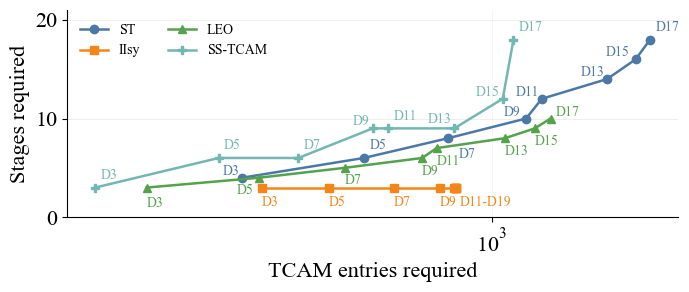

In [3]:
FEATURE_COUNT = 9
STAGE_LIMIT = 20
DATA_FILE = Path("data/all_dt_ciciot22.txt")

NON_DEPLOYABLE = {
    "failed",
    "missing_converter",
    "N/A",
    "pending",
    "skipped_after_failure",
}

COLUMNS = [
    "feature",
    "depth",
    "tree",
    "max_leaves",
    "leaves",
    "acc",
    "macro_f1",
    "st",
    "st_tcam",
    "iisy",
    "iisy_range",
    "leo_tcam",
    "leo_sram",
    "ss",
    "ss_greedy",
    "ss_range_sram",
    "ss_range_tcam",
]
SOURCE_COLUMNS = {
    "iisy": ("iisy", "iisy_range"),
    "leo": ("leo_tcam", "leo_sram"),
    "ss_light": ("ss", "ss_range_tcam"),
    "st": ("st", "st_tcam"),
}


@dataclass(frozen=True)
class MetricValue:
    entries: int
    rendered_blocks: int | None = None


@dataclass(frozen=True)
class Row:
    feature: int
    depth: int
    max_leaves: int | None
    macro_f1: float
    values: dict[str, MetricValue | None]


@dataclass(frozen=True)
class Point:
    depth: int
    max_leaves: int | None
    macro_f1: float
    entries: int
    stages: int


@dataclass(frozen=True)
class Scheme:
    key: str
    label: str
    marker: str
    color: str
    stage_count: Callable[[Row, MetricValue], int]


def stage_switchtree(row: Row, value: MetricValue) -> int:
    del value
    return row.depth + 1


def stage_iisy_range(row: Row, value: MetricValue) -> int:
    del row, value
    return 3


def stage_leo_tcam(row: Row, value: MetricValue) -> int:
    del value
    flattened_layers = math.ceil(row.depth / 2)
    return flattened_layers + 1


def stage_ss_range(row: Row, value: MetricValue) -> int:
    if value.rendered_blocks is None:
        raise ValueError("expected rendered block count")
    del row
    return value.rendered_blocks * 3


SCHEMES = [
    Scheme("st_tcam", "ST", "o", "#4C78A8", stage_switchtree),
    Scheme("iisy_range", "IIsy", "s", "#F58518", stage_iisy_range),
    Scheme("leo_tcam", "LEO", "^", "#54A24B", stage_leo_tcam),
    Scheme("ss_range_tcam", "SS-TCAM", "P", "#72B7B2", stage_ss_range),
]

DEFAULT_LABEL_OFFSET = (4, 4)
ANNOTATION_OFFSETS = {
    ("leo_tcam", 3): (0, -6),
    ("leo_tcam", 5): (-4, -4),
    ("leo_tcam", 7): (0, -4),
    ("leo_tcam", 9): (0, -4),
    ("leo_tcam", 11): (0, -4),
    ("leo_tcam", 13): (0, -4),
    ("leo_tcam", 15): (0, -4),
    ("leo_tcam", 17): (4, 0),
    ("st_tcam", 3): (-2, 0),
    ("st_tcam", 7): (8, -6),
    ("st_tcam", 9): (-4, 0),
    ("st_tcam", 11): (-2, 0),
    ("st_tcam", 13): (-2, 0),
    ("st_tcam", 15): (-4, 0),
    ("ss_range_tcam", 9): (-2, 0),
    ("ss_range_tcam", 13): (-2, 2),
    ("ss_range_tcam", 15): (-2, 0),
    ("iisy_range", 3): (0, -5),
    ("iisy_range", 5): (0, -5),
    ("iisy_range", 7): (0, -5),
    ("iisy_range", 9): (0, -5),
}


def parse_metric(text: str) -> MetricValue | None:
    text = text.strip()
    if text in NON_DEPLOYABLE:
        return None
    match = re.fullmatch(r"(?P<entries>\d+(?:,\s*\d+)*)(?:\s+\((?P<blocks>\d+)\))?", text)
    if match is None:
        raise ValueError(f"unexpected metric value: {text!r}")
    entries = [int(entry) for entry in match.group("entries").split(",")]
    blocks = match.group("blocks")
    return MetricValue(
        entries=entries[0],
        rendered_blocks=int(blocks) if blocks is not None else None,
    )


def parse_max_leaves(text: str) -> int | None:
    return None if text == "no_limit" else int(text)


def read_rows(path: Path) -> list[Row]:
    rows: list[Row] = []
    columns: list[str] = []
    for line in path.read_text(encoding="utf-8").splitlines():
        stripped = line.strip()
        if not stripped or stripped.startswith("-"):
            continue
        parts = re.split(r"\s{2,}", stripped)
        if not columns:
            columns = [
                re.sub(r"[ -]+", "_", name.lstrip("# ").lower().removesuffix(" entries")) for name in parts
            ]
            missing = set(COLUMNS) - set(columns)
            if missing:
                raise ValueError(f"missing required columns: {sorted(missing)}")
            if len(set(columns)) != len(columns):
                raise ValueError("duplicate column names")
            continue
        if stripped.startswith("#"):
            continue
        if len(parts) != len(columns):
            raise ValueError(f"expected {len(columns)} columns, found {len(parts)}: {line!r}")
        raw = dict(zip(columns, parts))
        rows.append(
            Row(
                feature=int(raw["feature"]),
                depth=int(raw["depth"]),
                max_leaves=parse_max_leaves(raw["max_leaves"]),
                macro_f1=float(raw["macro_f1"]),
                values={
                    key: parse_metric(raw[key])
                    for key in COLUMNS[7:]
                },
            )
        )
    if not columns:
        raise ValueError("missing column header")
    return rows


def point_for_row(row: Row, scheme: Scheme) -> Point | None:
    value = row.values.get(scheme.key)
    if value is None:
        return None
    stages = scheme.stage_count(row, value)
    if stages > STAGE_LIMIT:
        return None
    return Point(
        depth=row.depth,
        max_leaves=row.max_leaves,
        macro_f1=row.macro_f1,
        entries=value.entries,
        stages=stages,
    )


def dominates(left: Point, right: Point) -> bool:
    return (
        left.macro_f1 >= right.macro_f1
        and left.entries <= right.entries
        and left.stages <= right.stages
        and (
            left.macro_f1 > right.macro_f1
            or left.entries < right.entries
            or left.stages < right.stages
        )
    )


def equivalent(left: Point, right: Point) -> bool:
    return (
        left.entries == right.entries
        and left.stages == right.stages
        and math.isclose(left.macro_f1, right.macro_f1, rel_tol=0.0, abs_tol=1e-12)
    )


def unique_points(points: list[Point]) -> list[Point]:
    unique: list[Point] = []
    for point in points:
        if not any(equivalent(point, existing) for existing in unique):
            unique.append(point)
    return unique


def pareto_frontier(points: list[Point]) -> list[Point]:
    unique = unique_points(points)
    return [
        point
        for point in unique
        if not any(dominates(other, point) for other in unique if other is not point)
    ]


def representative_frontier_point(points: list[Point]) -> Point:
    frontier = pareto_frontier(points)
    return max(
        frontier,
        key=lambda point: (
            point.macro_f1,
            -point.stages,
            -point.entries,
        ),
    )


def selected_points(rows: list[Row], scheme: Scheme) -> list[Point]:
    points: list[Point] = []
    depths = sorted({row.depth for row in rows if row.feature == FEATURE_COUNT and row.depth % 2 == 1})
    best_macro_f1 = -math.inf
    for depth in depths:
        candidates = [
            (row, point)
            for row in rows
            if row.feature == FEATURE_COUNT
            and row.depth == depth
            for point in [point_for_row(row, scheme)]
            if point is not None
        ]
        if not candidates:
            break
        point = representative_frontier_point([point for _, point in candidates])
        if point.macro_f1 > best_macro_f1:
            points.append(point)
            best_macro_f1 = point.macro_f1
        else:
            break
    return points


def annotate_points(ax: plt.Axes, points: list[Point], scheme: Scheme) -> None:
    range_tail = []
    if scheme.key == "iisy_range":
        range_tail = [point for point in points if point.depth >= 11]

    for point in points:
        if scheme.key == "iisy_range" and point.depth >= 11:
            continue
        offset = ANNOTATION_OFFSETS.get((scheme.key, point.depth), DEFAULT_LABEL_OFFSET)
        ax.annotate(
            f"D{point.depth}",
            (point.entries, point.stages),
            textcoords="offset points",
            xytext=offset,
            ha="right" if offset[0] < 0 else "left",
            va="top" if offset[1] < 0 else "bottom",
            fontsize=10,
            color=scheme.color,
        )

    if range_tail:
        first_depth = min(point.depth for point in range_tail)
        last_depth = max(point.depth for point in range_tail)
        anchor = max(range_tail, key=lambda point: point.depth)
        ax.annotate(
            f"D{first_depth}-D{last_depth}",
            (anchor.entries, anchor.stages),
            textcoords="offset points",
            xytext=(4, -5),
            ha="left",
            va="top",
            fontsize=10,
            color=scheme.color,
        )


def plot() -> None:
    rows = read_rows(DATA_FILE)

    plt.rcParams.update(
        {
            "font.family": "Times New Roman",
            "font.serif": ["Times New Roman"],
            "font.size": 16,
            "mathtext.fontset": "custom",
            "mathtext.rm": "Times New Roman",
            "mathtext.it": "Times New Roman:italic",
            "mathtext.bf": "Times New Roman:bold",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    )

    fig, ax = plt.subplots(figsize=(7.2, 3.2))
    for scheme in SCHEMES:
        points = selected_points(rows, scheme)
        if not points:
            continue
        x_values = [point.entries for point in points]
        y_values = [point.stages for point in points]
        ax.plot(
            x_values,
            y_values,
            marker=scheme.marker,
            linewidth=1.8,
            markersize=6,
            label=scheme.label,
            color=scheme.color,
        )
        annotate_points(ax, points, scheme)

    ax.set_xscale("log")
    ax.set_ylim(0, STAGE_LIMIT + 1)
    ax.set_xlabel("TCAM entries required")
    ax.set_ylabel("Stages required")
    # ax.set_title(f"Decision trees, feature={FEATURE_COUNT}")
    ax.xaxis.set_major_locator(FixedLocator([10**3, 10**4, 10**5]))
    ax.xaxis.set_major_formatter(LogFormatterMathtext(base=10))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(True, axis="y", alpha=0.3)
    ax.grid(True, axis="x", alpha=0.15, which="major")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(fontsize=10, frameon=False, ncol=2)

    fig.tight_layout()
    plt.show()


plot()